# Optimized Hydrostatic Guideway Pocket Position Estimator

## Objective
To develop a Python-based analytical tool for determining the optimum locations of four rectangularly arranged hydrostatic bearing pockets in a machine tool guideway such that the maximum pocket load is minimized under static and uni-directional accelerated conditions.

---

## Methodology

1. The table dimensions, minimum permissible pocket margins, table properties, lead screw location, external loads and accelerations are provided as inputs.

2. The combined centre of gravity (CG) of the table and all external loads is calculated as

\[
X=\frac{\sum m_i x_i}{\sum m_i},
\qquad
Y=\frac{\sum m_i y_i}{\sum m_i},
\qquad
Z=\frac{\sum m_i z_i}{\sum m_i}
\]

The total weight is

\[
W=Mg
\]

where

\[
M=\sum m_i
\]

3. Initially, all four hydrostatic pockets are placed at the minimum permissible margins from the table edges. The pockets are constrained to always form a rectangle.

4. For static loading, the pocket pair nearest to the centre of load is kept fixed and the opposite pair is moved until all four pocket reactions become equal.

5. For uni-directional acceleration, the row carrying the larger normal force is kept fixed and the opposite row is moved towards the centre of load until equal load sharing is achieved.

6. After optimization, the pocket coordinates and support spans are recalculated and the optimized layout is visualized.

---

## Assumptions

1. The table behaves as a perfectly rigid body.
2. All hydrostatic pockets are identical.
3. Pocket reactions are represented as concentrated forces.
4. The lead screw force acts below the centre of gravity and produces an overturning moment equal to

\[
Mah
\]

where

\[
h = Z-z_{ls}
\]

5. The four pockets always form a rectangle.
6. Only static loading or uni-directional acceleration is considered.
7. Equal load sharing minimizes the maximum pocket reaction.

---

## Limitations

- Fluid film stiffness is neglected.
- Pressure distribution inside the pockets is neglected.
- Restrictor characteristics are neglected.
- Structural deformation of the table is neglected.
- Dynamic squeeze-film effects are neglected.
- Simultaneous bi-directional accelerations are not considered.

---

## Output

The program computes:

- Combined centre of gravity
- Optimized pocket coordinates
- Optimized support spans
- Pocket reactions
- Graphical representation of the optimized hydrostatic guideway layout


OPTIMIZED POSITION OF POCKETS ESTIMATOR



Table length (mm):  700
Table breadth (mm):  400
Table height (mm):  70
Pocket min margin in x-direction (mm):  30
Pocket min margin in y-direction (mm):  30
Acceleration due to gravity (m/s²):  10
Mass of table (kg):  50
Table CG x-coordinate (mm):  50
Table CG y-coordinate (mm):  50
Table CG z-coordinate (mm):  70
Lead screw x-coordinate (mm):  50
Lead screw y-coordinate (mm):  50
Lead screw z-coordinate (mm):  10
Acceleration in x-direction (m/s²):  7
Acceleration in y-direction (m/s²):  0
Number of external loads:  2



Load 1


Mass (kg):  10
x-coordinate (mm):  200
y-coordinate (mm):  200
z-coordinate (mm):  80



Load 2


Mass (kg):  30
x-coordinate (mm):  150
y-coordinate (mm):  150
z-coordinate (mm):  90



========== OPTIMIZED RESULTS ==========
Total mass      : 90.000 kg
Total weight    : 900.000 N

Combined CG
X = 100.00 mm
Y = 100.00 mm
Z = 77.78 mm

Optimized pocket coordinates
P1 = (-264.89, -20.00)
P2 = (-264.89, 220.00)
P3 = (370.00, -20.00)
P4 = (370.00, 220.00)

Support span in X = 634.89 mm
Support span in Y = 240.00 mm

Pocket reactions
N1 = 225.00 N
N2 = 225.00 N
N3 = 225.00 N
N4 = 225.00 N
Sum = 900.00 N


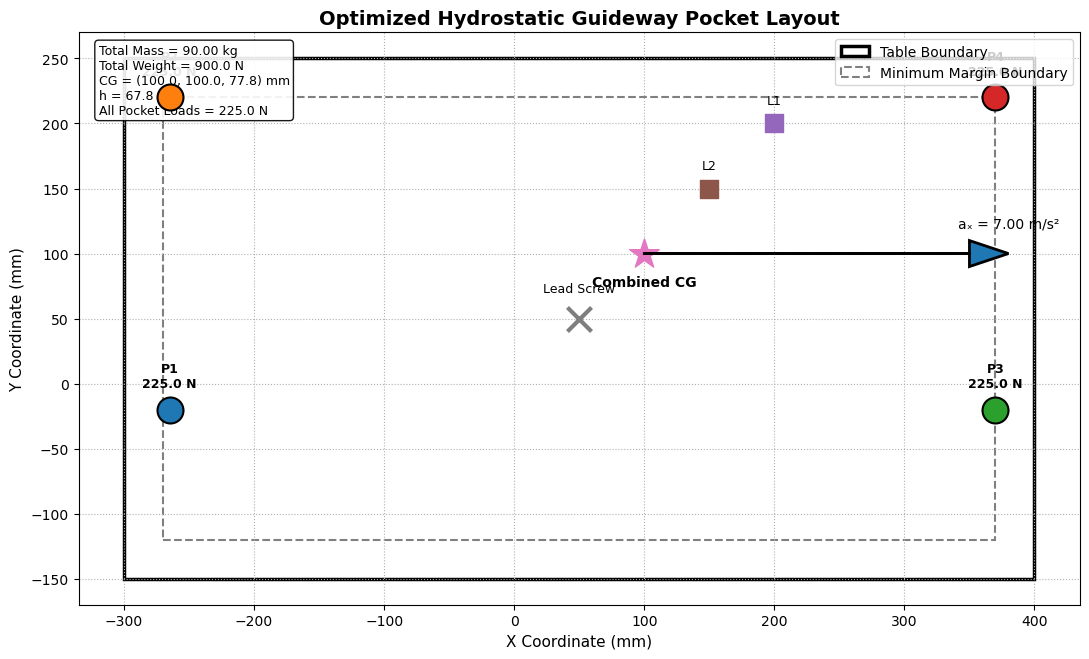

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ==========================================
# INPUTS
# ==========================================
print("\nOPTIMIZED POSITION OF POCKETS ESTIMATOR\n")

# Table dimensions
length = float(input("Table length (mm): "))
breadth = float(input("Table breadth (mm): "))
height = float(input("Table height (mm): "))
margin_x = float(input("Pocket min margin in x-direction (mm): "))
margin_y = float(input("Pocket min margin in y-direction (mm): "))

# Gravity
g = float(input("Acceleration due to gravity (m/s²): "))

# Table properties
m_table = float(input("Mass of table (kg): "))
x_table = float(input("Table CG x-coordinate (mm): "))
y_table = float(input("Table CG y-coordinate (mm): "))
z_table = float(input("Table CG z-coordinate (mm): "))

# Lead screw location
x_ls = float(input("Lead screw x-coordinate (mm): "))
y_ls = float(input("Lead screw y-coordinate (mm): "))
z_ls = float(input("Lead screw z-coordinate (mm): "))

# Accelerations
a_x = float(input("Acceleration in x-direction (m/s²): "))
a_y = float(input("Acceleration in y-direction (m/s²): "))

# ==========================================
# LOAD INPUTS
# ==========================================
total_mass = m_table
sum_mx = m_table * x_table
sum_my = m_table * y_table
sum_mz = m_table * z_table

load_x, load_y = [], []

n = int(input("Number of external loads: "))

for i in range(n):
    print(f"\nLoad {i+1}")

    m = float(input("Mass (kg): "))
    x = float(input("x-coordinate (mm): "))
    y = float(input("y-coordinate (mm): "))
    z = float(input("z-coordinate (mm): "))

    total_mass += m
    sum_mx += m * x
    sum_my += m * y
    sum_mz += m * z
    
    load_x.append(x)
    load_y.append(y)

# ==========================================
# COMBINED CG
# ==========================================
X = sum_mx / total_mass
Y = sum_my / total_mass
Z = sum_mz / total_mass

Total_W = total_mass * g
h = Z - z_ls

# ==========================================
# POCKET LOCATIONS WITH MINIMUM MARGIN
# ==========================================
x_b = x_table - length / 2 + margin_x
x_f = x_table + length / 2 - margin_x
y_r = y_table - breadth / 2 + margin_y
y_l = y_table + breadth / 2 - margin_y

xp_span = length - 2 * margin_x
yp_span = breadth - 2 * margin_y

b2c = X - x_b
f2c = x_f - X
r2c = Y - y_r
l2c = y_l - Y

# ==========================================
# OPTIMIZATION
# ==========================================
tol = 1e-9

if abs(a_x) < tol and abs(a_y) < tol:

    # In x-axis
    if b2c <= f2c:
        f2c = b2c
    else:
        b2c = f2c

    # In Y-axis
    if r2c <= l2c:
        l2c = r2c
    else:
        r2c = l2c

elif abs(a_x) > tol and abs(a_y) < tol:

    My = total_mass * a_x * h

    Nb = (Total_W * f2c + My) / xp_span
    Nf = (Total_W * b2c - My) / xp_span

    # In x-axis
    if Nb >= Nf:
        f2c = 2*(Total_W*b2c/2 - My)/Total_W
    else:
        b2c = 2*(Total_W*f2c/2 + My)/Total_W

    # In Y-axis
    if r2c <= l2c:
        l2c = r2c
    else:
        r2c = l2c

elif abs(a_x) < tol and abs(a_y) > tol:

    Mx = total_mass * a_y * h

    Nr = (Total_W * l2c + Mx) / yp_span
    Nl = (Total_W * r2c - Mx) / yp_span

    # In x-axis
    if b2c <= f2c:
        f2c = b2c
    else:
        b2c = f2c

    # In Y-axis
    if Nr >= Nl:
        l2c = 2*(Total_W*r2c/2 - Mx)/Total_W
    else:
        r2c = 2*(Total_W*l2c/2 + Mx)/Total_W

else:
    print("\nSimultaneous accelerations detected.")
    print("Cannot be optimized with this model.")
    exit()    

# ==========================================
# RECOMPUTE POCKET COORDINATES
# ==========================================
x_b = X - b2c
x_f = X + f2c
y_r = Y - r2c
y_l = Y + l2c

xp_span = b2c + f2c
yp_span = r2c + l2c

# ==========================================
# FINAL POCKET REACTIONS
# ==========================================
N1 = Total_W / 4
N2 = Total_W / 4
N3 = Total_W / 4
N4 = Total_W / 4

print("\n========== OPTIMIZED RESULTS ==========")

print(f"Total mass      : {total_mass:.3f} kg")
print(f"Total weight    : {Total_W:.3f} N")

print(f"\nCombined CG")
print(f"X = {X:.2f} mm")
print(f"Y = {Y:.2f} mm")
print(f"Z = {Z:.2f} mm")

print(f"\nOptimized pocket coordinates")

print(f"P1 = ({x_b:.2f}, {y_r:.2f})")
print(f"P2 = ({x_b:.2f}, {y_l:.2f})")
print(f"P3 = ({x_f:.2f}, {y_r:.2f})")
print(f"P4 = ({x_f:.2f}, {y_l:.2f})")

print(f"\nSupport span in X = {xp_span:.2f} mm")
print(f"Support span in Y = {yp_span:.2f} mm")

print(f"\nPocket reactions")
print(f"N1 = {N1:.2f} N")
print(f"N2 = {N2:.2f} N")
print(f"N3 = {N3:.2f} N")
print(f"N4 = {N4:.2f} N")
print(f"Sum = {N1+N2+N3+N4:.2f} N")

# ==========================================
# VISUALIZATION
# ==========================================
fig, ax = plt.subplots(figsize=(11, 8))

# ------------------------------------------
# Table Boundary
# ------------------------------------------
table_x = x_table - length/2
table_y = y_table - breadth/2

table = patches.Rectangle(
    (table_x, table_y),
    length,
    breadth,
    fill=False,
    linewidth=2.5,
    edgecolor='black'
)

ax.add_patch(table)

# ------------------------------------------
# Minimum Margin Rectangle
# ------------------------------------------
margin_rect = patches.Rectangle(
    (table_x + margin_x,
     table_y + margin_y),
    length - 2*margin_x,
    breadth - 2*margin_y,
    fill=False,
    linestyle='--',
    linewidth=1.5,
    edgecolor='gray'
)

ax.add_patch(margin_rect)

# ------------------------------------------
# Optimized Pocket Locations
# ------------------------------------------
px = [x_b, x_b, x_f, x_f]
py = [y_r, y_l, y_r, y_l]
labels = ["P1", "P2", "P3", "P4"]
forces = [N1, N2, N3, N4]

for x, y, p, n in zip(px, py, labels, forces):

    ax.scatter(
        x,
        y,
        s=350,
        marker='o',
        edgecolors='black',
        linewidths=1.5,
        zorder=5
    )

    ax.text(
        x,
        y + 15,
        f"{p}\n{n:.1f} N",
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

# ------------------------------------------
# External Loads
# ------------------------------------------
for i, (x, y) in enumerate(zip(load_x, load_y)):

    ax.scatter(
        x,
        y,
        s=180,
        marker='s',
        zorder=6
    )

    ax.text(
        x,
        y + 15,
        f"L{i+1}",
        ha='center',
        fontsize=9
    )

# ------------------------------------------
# Combined CG
# ------------------------------------------
ax.scatter(
    X,
    Y,
    marker='*',
    s=500,
    zorder=7
)

ax.text(
    X,
    Y - 25,
    "Combined CG",
    ha='center',
    fontsize=10,
    fontweight='bold'
)

# ------------------------------------------
# Lead Screw Location
# ------------------------------------------
ax.scatter(
    x_ls,
    y_ls,
    marker='x',
    s=300,
    linewidths=3,
    zorder=7
)

ax.text(
    x_ls,
    y_ls + 20,
    "Lead Screw",
    ha='center',
    fontsize=9
)

# ------------------------------------------
# Acceleration Direction
# ------------------------------------------
scale = 40

if abs(a_x) > tol:
    ax.arrow(
        X,
        Y,
        scale * a_x,
        0,
        head_width=20,
        length_includes_head=True,
        linewidth=2,
        zorder=8
    )

    ax.text(
        X + scale*a_x,
        Y + 20,
        f"aₓ = {a_x:.2f} m/s²",
        ha='center'
    )

if abs(a_y) > tol:
    ax.arrow(
        X,
        Y,
        0,
        scale * a_y,
        head_width=20,
        length_includes_head=True,
        linewidth=2,
        zorder=8
    )

    ax.text(
        X + 20,
        Y + scale*a_y,
        f"aᵧ = {a_y:.2f} m/s²",
        ha='left'
    )

# ------------------------------------------
# Information Box
# ------------------------------------------
info = (
    f"Total Mass = {total_mass:.2f} kg\n"
    f"Total Weight = {Total_W:.1f} N\n"
    f"CG = ({X:.1f}, {Y:.1f}, {Z:.1f}) mm\n"
    f"h = {h:.1f} mm\n"
    f"All Pocket Loads = {Total_W/4:.1f} N"
)

ax.text(
    0.02,
    0.98,
    info,
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.9
    )
)

# ------------------------------------------
# Formatting
# ------------------------------------------
ax.set_aspect('equal')
ax.set_xlabel('X Coordinate (mm)', fontsize=11)
ax.set_ylabel('Y Coordinate (mm)', fontsize=11)
ax.set_title(
    'Optimized Hydrostatic Guideway Pocket Layout',
    fontsize=14,
    fontweight='bold'
)

ax.grid(True, linestyle=':')
ax.legend(
    [
        table,
        margin_rect
    ],
    [
        'Table Boundary',
        'Minimum Margin Boundary'
    ],
    loc='upper right'
)

plt.tight_layout()
plt.savefig(
    'Optimized_Hydrostatic_Guideway.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()